In [1]:
import os
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
import lightgbm as lgb

t0 = time.time()

# Auto-locate competition files under /kaggle/input
train_path = test_path = sub_path = None
for root, _, files in os.walk("/kaggle/input"):
    for f in files:
        full = os.path.join(root, f)
        if f.startswith("train.csv"):
            train_path = full
        elif f.startswith("test.csv"):
            test_path = full
        elif f.startswith("sample_submission.csv"):
            sub_path = full

train_path = train_path or "train.csv.gz"
test_path  = test_path  or "test.csv"
sub_path   = sub_path   or "sample_submission.csv"

train_df = pd.read_csv(train_path, low_memory=False)
test_df  = pd.read_csv(test_path, low_memory=False)
sub_df   = pd.read_csv(sub_path, low_memory=False)
print(f"[1] Loaded in {time.time() - t0:.1f}s | train={train_df.shape}, test={test_df.shape}")

[1] Loaded in 8.1s | train=(279746, 60), test=(114538, 59)


=== Target Distribution (price_tier) ===
price_tier
1    66889
2    81530
3    60839
4    70488
Name: count, dtype: int64

=== Top Missing Columns (%) ===
borough              76.66
score_value          19.39
score_access         19.39
score_onboarding     19.39
score_accuracy       19.39
score_support        19.39
first_review_date    19.39
last_review_date     19.39
score_condition      19.39
reviews_per_month    19.39
dtype: float64


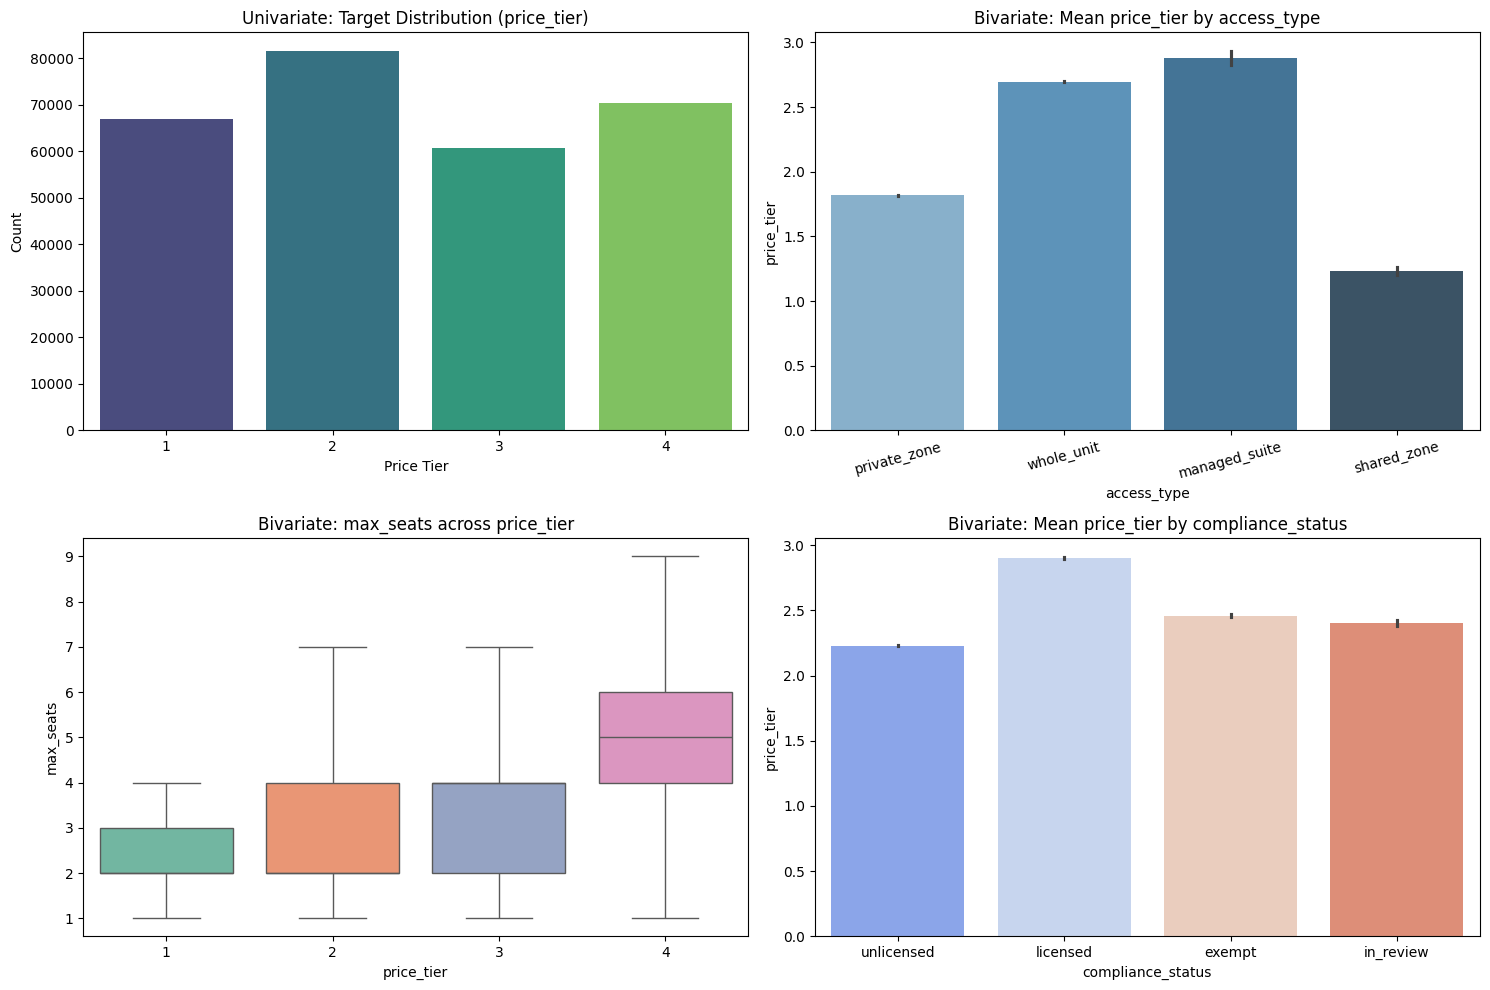

In [2]:
# 1. Target balance & missing value summary
print("=== Target Distribution (price_tier) ===")
print(train_df["price_tier"].value_counts().sort_index())

na_pct = (train_df.isna().mean() * 100).sort_values(ascending=False)
print("\n=== Top Missing Columns (%) ===")
print(na_pct[na_pct > 0].head(10).round(2))

# 2. Univariate & Bivariate Visualizations
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Plot 1: Target distribution
sns.countplot(data=train_df, x="price_tier", palette="viridis", ax=axes[0, 0])
axes[0, 0].set_title("Univariate: Target Distribution (price_tier)")
axes[0, 0].set_xlabel("Price Tier")
axes[0, 0].set_ylabel("Count")

# Plot 2: Bivariate - Access Type vs Price Tier
sns.barplot(data=train_df, x="access_type", y="price_tier", estimator="mean", palette="Blues_d", ax=axes[0, 1])
axes[0, 1].set_title("Bivariate: Mean price_tier by access_type")
axes[0, 1].tick_params(axis="x", rotation=15)

# Plot 3: Bivariate - Max Seats vs Price Tier
sns.boxplot(data=train_df, x="price_tier", y="max_seats", showfliers=False, palette="Set2", ax=axes[1, 0])
axes[1, 0].set_title("Bivariate: max_seats across price_tier")

# Plot 4: Bivariate - Compliance Status vs Price Tier
sns.barplot(data=train_df, x="compliance_status", y="price_tier", estimator="mean", palette="coolwarm", ax=axes[1, 1])
axes[1, 1].set_title("Bivariate: Mean price_tier by compliance_status")

plt.tight_layout()
plt.show()

In [3]:
t1 = time.time()

# Extract ALL 144 FCL-* facility binary indicators (fast sparse -> int8)
vec = CountVectorizer(token_pattern=r"FCL-\d+", binary=True, lowercase=False)
F_tr = vec.fit_transform(train_df["facilities"].fillna("")).toarray().astype(np.int8)
F_te = vec.transform(test_df["facilities"].fillna("")).toarray().astype(np.int8)
fac_cols = [f"fac_{c}" for c in vec.get_feature_names_out()]

def build_features(df: pd.DataFrame) -> pd.DataFrame:
    out = df.drop(columns=["price_tier", "space_id"], errors="ignore").copy()

    s = out["facilities"].fillna("").astype(str)
    out["facility_count"] = np.where(s.str.len() > 2, s.str.count(",") + 1, 0).astype("float32")
    out = out.drop(columns=["facilities"])

    for dcol in ["snapshot_start_date", "snapshot_end_date", "first_review_date", "last_review_date"]:
        if dcol in out.columns:
            dt = pd.to_datetime(out[dcol], format="%Y-%m-%d", errors="coerce")
            out[f"{dcol}_yr"] = dt.dt.year.astype("float32")
            out[f"{dcol}_mo"] = dt.dt.month.astype("float32")
            out[f"{dcol}_ord"] = np.where(
                dt.notna(), dt.values.astype("datetime64[D]").astype("float64"), np.nan
            ).astype("float32")
            out = out.drop(columns=[dcol])

    out["snapshot_span_days"] = (out["snapshot_end_date_ord"] - out["snapshot_start_date_ord"]).astype("float32")
    out["review_span_days"] = (out["last_review_date_ord"] - out["first_review_date_ord"]).astype("float32")
    out["days_since_last_review"] = (out["snapshot_end_date_ord"] - out["last_review_date_ord"]).astype("float32")

    out["has_reviews"] = (out["review_count"] > 0).astype(np.int8)
    out["has_borough"] = out["borough"].notna().astype(np.int8)
    out["missing_cnt"] = out.isna().sum(axis=1).astype("float32")

    out["op_platform_months"] = (
        out["operator_platform_age_years"].fillna(0) * 12 + out["operator_platform_age_months"].fillna(0)
    ).astype("float32")
    out["op_active_months"] = (
        out["operator_active_years"].fillna(0) * 12 + out["operator_active_months"].fillna(0)
    ).astype("float32")
    out["op_inactive_gap"] = (out["op_platform_months"] - out["op_active_months"]).astype("float32")

    out["seats_per_ws"] = (out["max_seats"] / (out["workstations"].fillna(0) + 1.0)).astype("float32")
    out["seats_per_zone"] = (out["max_seats"] / (out["zones"].fillna(0) + 1.0)).astype("float32")
    out["ws_per_zone"] = (out["workstations"].fillna(0) / (out["zones"].fillna(0) + 1.0)).astype("float32")
    out["util_per_seat"] = (out["utility_rooms"].fillna(0) / (out["max_seats"] + 1.0)).astype("float32")
    out["fac_per_seat"] = (out["facility_count"] / (out["max_seats"] + 1.0)).astype("float32")
    out["metro_share"] = (out["operator_metro_units"] / (out["operator_portfolio_size"].fillna(0) + 1.0)).astype("float32")
    out["whole_share"] = (out["operator_metro_whole"] / (out["operator_metro_units"] + 1.0)).astype("float32")
    out["private_share"] = (out["operator_metro_private"] / (out["operator_metro_units"] + 1.0)).astype("float32")
    out["load_per_seat"] = (out["booked_load"] / (out["max_seats"] + 1.0)).astype("float32")
    out["recent_12m_ratio"] = (out["review_count_12m"] / (out["review_count"] + 1.0)).astype("float32")
    out["slot_sum_ade"] = (out["open_slots_a"] + out["open_slots_d"] + out["open_slots_e"]).astype("float32")
    out["slot_ratio_ad"] = (out["open_slots_a"] / (out["open_slots_d"] + 1.0)).astype("float32")

    score_cols = [
        "score_overall", "score_accuracy", "score_condition",
        "score_onboarding", "score_support", "score_access", "score_value"
    ]
    out["score_mean_7"] = out[score_cols].mean(axis=1).astype("float32")
    out["score_std_7"] = out[score_cols].std(axis=1).astype("float32")
    out["score_val_diff"] = (out["score_overall"] - out["score_value"]).astype("float32")

    out["metro_access"] = out["metro"].fillna("NA").astype(str) + "_" + out["access_type"].fillna("NA").astype(str)
    out["metro_comp"] = out["metro"].fillna("NA").astype(str) + "_" + out["compliance_status"].fillna("NA").astype(str)
    out["zone_access"] = out["zone"].fillna("NA").astype(str) + "_" + out["access_type"].fillna("NA").astype(str)

    for col, cap in [("max_term_days", 3650.0), ("max_term_floor", 3650.0),
                      ("max_term_ceiling", 3650.0), ("max_term_avg", 3650.0),
                      ("reviews_per_month", 30.0)]:
        if col in out.columns:
            out[col] = np.clip(out[col].astype("float64"), 0.0, cap).astype("float32")

    return out

y = train_df["price_tier"].values.astype(np.int8)
X_tr = build_features(train_df)
X_te = build_features(test_df)

# Unlabelled spatial, frequency & operator aggregations (zero target leakage)
n_tr = len(X_tr)
both = pd.concat([X_tr, X_te], axis=0, ignore_index=True)

for grp in ["metro", "zone"]:
    lat_m = both.groupby(grp)["geo_lat"].transform("mean")
    lon_m = both.groupby(grp)["geo_lon"].transform("mean")
    both[f"dist_{grp}_center"] = np.sqrt((both["geo_lat"] - lat_m) ** 2 + (both["geo_lon"] - lon_m) ** 2).astype("float32")

for gcol in ["operator_ref", "zone", "space_class", "metro", "borough", "metro_access", "zone_access"]:
    freq = both[gcol].value_counts(normalize=True)
    both[f"{gcol}_freq"] = both[gcol].map(freq).fillna(0.0).astype("float32")

for nf in ["max_seats", "facility_count", "workstations", "booked_load"]:
    op_m = both.groupby("operator_ref")[nf].transform("mean")
    both[f"op_mean_{nf}"] = op_m.astype("float32")
    both[f"op_diff_{nf}"] = (both[nf] - op_m).astype("float32")

for grp, nf in [("metro", "max_seats"), ("metro", "facility_count"), ("zone", "max_seats"), ("metro_access", "max_seats")]:
    gm = both.groupby(grp)[nf].transform("mean")
    both[f"{nf}_diff_{grp}"] = (both[nf] - gm).astype("float32")

cat_cols = both.select_dtypes(include="object").columns.tolist()
for c in cat_cols:
    both[c] = both[c].fillna("MISSING").astype("category").cat.codes.astype("int32")

X_tr = pd.concat([both.iloc[:n_tr].reset_index(drop=True), pd.DataFrame(F_tr, columns=fac_cols)], axis=1)
X_te = pd.concat([both.iloc[n_tr:].reset_index(drop=True), pd.DataFrame(F_te, columns=fac_cols)], axis=1)
del both, F_tr, F_te

print(f"[2] Features ready in {time.time() - t1:.1f}s | shape={X_tr.shape}")

[2] Features ready in 14.6s | shape=(279746, 258)



=== 3-Model Family Comparison ===
                Model Family  Val Accuracy  Val Macro-F1  Fit Time (s)
 Linear (LogisticRegression)       0.63589       0.62585          30.7
      Bagging (RandomForest)       0.68933       0.68180          42.6
Gradient Boosting (LightGBM)       0.74361       0.73940         149.4

=== Classification Report (LightGBM) ===
              precision    recall  f1-score   support

           1       0.83      0.85      0.84     13378
           2       0.68      0.75      0.71     16306
           3       0.63      0.55      0.59     12168
           4       0.83      0.81      0.82     14098

    accuracy                           0.74     55950
   macro avg       0.74      0.74      0.74     55950
weighted avg       0.74      0.74      0.74     55950



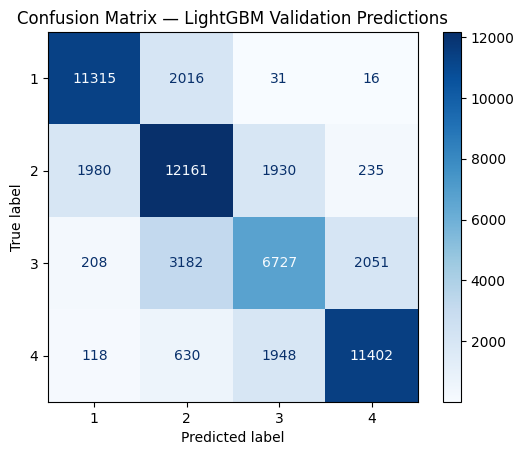

In [4]:
# Compare 3 distinct model families on a stratified 80/20 validation split using leak-free Pipelines
X_tr_sub, X_va_sub, y_tr_sub, y_va_sub = train_test_split(
    X_tr, y, test_size=0.20, stratify=y, random_state=42
)

all_cols = X_tr.columns.tolist()

linear_pipe = Pipeline([
    ("prep", ColumnTransformer([("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), all_cols)])),
    ("clf", LogisticRegression(max_iter=300, tol=1e-3, random_state=42)),
])

rf_pipe = Pipeline([
    ("prep", ColumnTransformer([("num", SimpleImputer(strategy="median"), all_cols)])),
    ("clf", RandomForestClassifier(
        n_estimators=80, max_depth=14, min_samples_leaf=10,
        n_jobs=-1, random_state=42
    )),
])

lgb_bench = lgb.LGBMClassifier(
    objective="multiclass", num_class=4, n_estimators=400,
    learning_rate=0.07, num_leaves=63, min_child_samples=40,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.6,
    reg_alpha=0.5, reg_lambda=2.0, n_jobs=-1, random_state=42, verbose=-1
)

results = []

# Model 1: Linear
t_m = time.time()
linear_pipe.fit(X_tr_sub, y_tr_sub)
p_lr = linear_pipe.predict(X_va_sub)
results.append({"Model Family": "Linear (LogisticRegression)", "Val Accuracy": round(accuracy_score(y_va_sub, p_lr), 5), "Val Macro-F1": round(f1_score(y_va_sub, p_lr, average="macro"), 5), "Fit Time (s)": round(time.time() - t_m, 1)})

# Model 2: Bagging Ensemble
t_m = time.time()
rf_pipe.fit(X_tr_sub, y_tr_sub)
p_rf = rf_pipe.predict(X_va_sub)
results.append({"Model Family": "Bagging (RandomForest)", "Val Accuracy": round(accuracy_score(y_va_sub, p_rf), 5), "Val Macro-F1": round(f1_score(y_va_sub, p_rf, average="macro"), 5), "Fit Time (s)": round(time.time() - t_m, 1)})

# Model 3: Gradient Boosting
t_m = time.time()
lgb_bench.fit(
    X_tr_sub, y_tr_sub - 1,
    eval_set=[(X_va_sub, y_va_sub - 1)],
    callbacks=[lgb.early_stopping(30, verbose=False)],
)
p_lgb = lgb_bench.predict(X_va_sub) + 1
results.append({"Model Family": "Gradient Boosting (LightGBM)", "Val Accuracy": round(accuracy_score(y_va_sub, p_lgb), 5), "Val Macro-F1": round(f1_score(y_va_sub, p_lgb, average="macro"), 5), "Fit Time (s)": round(time.time() - t_m, 1)})

comp_df = pd.DataFrame(results)
print("\n=== 3-Model Family Comparison ===")
print(comp_df.to_string(index=False))

# Error analysis on the best-performing family (LightGBM)
print("\n=== Classification Report (LightGBM) ===")
print(classification_report(y_va_sub, p_lgb))

ConfusionMatrixDisplay.from_predictions(y_va_sub, p_lgb, cmap="Blues")
plt.title("Confusion Matrix — LightGBM Validation Predictions")
plt.show()

del X_tr_sub, X_va_sub, y_tr_sub, y_va_sub, linear_pipe, rf_pipe, lgb_bench

In [ ]:
lgb_cats = [c for c in cat_cols if c != "operator_ref"]

skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
oof_lgb = np.zeros((n_tr, 4), dtype=np.float64)
oof_hgb = np.zeros((n_tr, 4), dtype=np.float64)
test_lgb = np.zeros((len(X_te), 4), dtype=np.float64)
test_hgb = np.zeros((len(X_te), 4), dtype=np.float64)

for fold, (tr_idx, va_idx) in enumerate(skf.split(X_tr, y)):
    tf = time.time()

    gbm = lgb.LGBMClassifier(
        objective="multiclass",
        num_class=4,
        n_estimators=900,
        learning_rate=0.05,
        num_leaves=95,
        min_child_samples=35,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.7,
        reg_alpha=0.5,
        reg_lambda=2.0,
        n_jobs=4,
        random_state=42 + fold,
        verbose=-1,
    )
    gbm.fit(
        X_tr.iloc[tr_idx], y[tr_idx] - 1,
        eval_set=[(X_tr.iloc[va_idx], y[va_idx] - 1)],
        categorical_feature=lgb_cats,
        callbacks=[lgb.early_stopping(40, verbose=False)],
    )
    oof_lgb[va_idx] = gbm.predict_proba(X_tr.iloc[va_idx])
    test_lgb += gbm.predict_proba(X_te) / 3.0

    hgb = HistGradientBoostingClassifier(
        learning_rate=0.06,
        max_iter=260,
        max_leaf_nodes=95,
        min_samples_leaf=30,
        l2_regularization=2.0,
        early_stopping=True,
        n_iter_no_change=15,
        random_state=42 + fold,
    )
    hgb.fit(X_tr.iloc[tr_idx], y[tr_idx])
    oof_hgb[va_idx] = hgb.predict_proba(X_tr.iloc[va_idx])
    test_hgb += hgb.predict_proba(X_te) / 3.0

    print(
        f"[3] Fold {fold + 1} | LGB Acc={accuracy_score(y[va_idx], oof_lgb[va_idx].argmax(1)+1):.5f} "
        f"| HGB Acc={accuracy_score(y[va_idx], oof_hgb[va_idx].argmax(1)+1):.5f} | {time.time() - tf:.1f}s"
    )

lgb_pred = oof_lgb.argmax(axis=1) + 1
hgb_pred = oof_hgb.argmax(axis=1) + 1
print(f"\nOOF LGB | Acc={accuracy_score(y, lgb_pred):.5f} | Macro-F1={f1_score(y, lgb_pred, average='macro'):.5f}")
print(f"OOF HGB | Acc={accuracy_score(y, hgb_pred):.5f} | Macro-F1={f1_score(y, hgb_pred, average='macro'):.5f}")

best_w, best_acc = 0.7, 0.0
for w in np.linspace(0.0, 1.0, 21):
    p = (w * oof_lgb + (1 - w) * oof_hgb).argmax(axis=1) + 1
    acc = accuracy_score(y, p)
    if acc > best_acc:
        best_acc, best_w = acc, w

blend_oof = (best_w * oof_lgb + (1 - best_w) * oof_hgb).argmax(axis=1) + 1
print(
    f"OOF Blend (w_lgb={best_w:.2f}) | Acc={best_acc:.5f} "
    f"| Macro-F1={f1_score(y, blend_oof, average='macro'):.5f} | Total={time.time() - t0:.1f}s"
)

# Save & verify submission.csv
final_proba = best_w * test_lgb + (1 - best_w) * test_hgb
sub = pd.DataFrame({
    "ID": sub_df["ID"],
    "price_tier": (final_proba.argmax(axis=1) + 1).astype(int),
})
sub.to_csv("/kaggle/working/submission.csv", index=False)

assert os.path.exists("/kaggle/working/submission.csv") and len(sub) == 114538
assert sub["price_tier"].isna().sum() == 0
print("Verified /kaggle/working/submission.csv:", sub.shape)
print(sub["price_tier"].value_counts().sort_index())

[3] Fold 1 | LGB Acc=0.73969 | HGB Acc=0.73591 | 746.9s
